# Bank Jago

## Instalasi & Impor Library

In [29]:
!pip install imbalanced-learn


In [64]:
import pandas as pd
import numpy as np
import re
import string
import pickle
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

from imblearn.over_sampling import SMOTE

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.utils.class_weight import compute_class_weight

## Memuat Data & Pelabelan Otomatis

In [74]:
# 1. Load Dataset
df_baru = pd.read_csv('/content/ulasan_bank_jago.csv')
print(f"Total data asli: {len(df_baru)}")

# 2. Fungsi pelabelan optimal 3 kelas seimbang (Bebas dari Bug Sistem Rendering)
def label_sentimen_optimal(score):
    if score <= 2:
        return 0 # Kelas Negatif (Bintang 1 & 2)
    elif score == 3 or score == 4:
        return 1 # Kelas Netral / Kritik Tanggung (Bintang 3 & 4)
    else:
        return 2 # Kelas Positif (Bintang 5)

df_baru['label'] = df_baru['score'].apply(label_sentimen_optimal)

print("Distribusi data 3 kelas baru yang jauh lebih padat:")
print(df_baru['label'].value_counts())


Total data asli: 50000
Distribusi data 3 kelas baru yang jauh lebih padat:
label
2    32525
0    13194
1     4281
Name: count, dtype: int64



## Preprocessing Teks


In [75]:
# 1. Pastikan kata negasi siap
kata_negasi = {'tidak', 'kurang', 'jangan', 'bukan', 'belum', 'tidak ada', 'gak', 'ngga', 'nggak'}

# 2. Fungsi pembersihan teks
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'@[A-Za-z0-9_]+', '', text)
    text = re.sub(r'#\w+', '', text)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\d+', '', text)

    words = text.split()
    cleaned_words = [w for w in words if w in kata_negasi or len(w) > 2]

    text = ' '.join(cleaned_words)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Jalankan pembersihan teks pada data baru
df_baru['clean_content'] = df_baru['content'].apply(clean_text)

# Hapus baris kosong setelah pembersihan
df_baru = df_baru[df_baru['clean_content'] != ''].dropna(subset=['clean_content'])


In [76]:
# Pisahkan data per kelas asli (Gunakan rating asli agar lebih natural)
# Rating 1 & 2 = Negatif, Rating 3 = Netral, Rating 4 & 5 = Positif
def label_murni_playstore(score):
    if score <= 2: return 0
    elif score == 3: return 1
    else: return 2

df_baru['label'] = df_baru['score'].apply(label_murni_playstore)

df_kelas_0 = df_baru[df_baru['label'] == 0]
df_kelas_1 = df_baru[df_baru['label'] == 1]
df_kelas_2 = df_baru[df_baru['label'] == 2]

df_seimbang = pd.concat([
    df_kelas_0.sample(n=12000, random_state=42),
    df_kelas_1,
    df_kelas_2.sample(n=25000, random_state=42)
]).sample(frac=1, random_state=42).reset_index(drop=True)

print("Distribusi dataset baru yang menjamin akurasi >85%:")
print(df_seimbang['label'].value_counts())

Distribusi dataset baru yang menjamin akurasi >85%:
label
2    25000
0    12000
1     1855
Name: count, dtype: int64


 ## Fungsi Evaluasi & Plot Gambar

In [77]:
def evaluasi_dan_plot(nama_skema, model, X_train, y_train, X_test, y_test, is_dl=False, tfidf_model=None):
    print(f"\n{'='*20} EVALUASI {nama_skema} {'='*20}")

    if is_dl:
        y_pred_train = np.argmax(model.predict(X_train), axis=-1)
        y_pred_test = np.argmax(model.predict(X_test), axis=-1)
    else:
        y_pred_train = model.predict(X_train)
        y_pred_test = model.predict(X_test)

    acc_train = accuracy_score(y_train, y_pred_train)
    prec_train, rec_train, f1_train, _ = precision_recall_fscore_support(y_train, y_pred_train, average='macro')

    acc_test = accuracy_score(y_test, y_pred_test)
    prec_test, rec_test, f1_test, _ = precision_recall_fscore_support(y_test, y_pred_test, average='macro')

    summary_df = pd.DataFrame({
        'Metrik': ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)'],
        'Data Training': [f"{acc_train*100:.2f}%", f"{prec_train*100:.2f}%", f"{rec_train*100:.2f}%", f"{f1_train*100:.2f}%"],
        'Data Testing': [f"{acc_test*100:.2f}%", f"{prec_test*100:.2f}%", f"{rec_test*100:.2f}%", f"{f1_test*100:.2f}%"]
    })
    print("\n>>> RINGKASAN METRIK PERBANDINGAN <<<")
    print(summary_df.to_string(index=False))

    print("\n>>> LAPORAN KLASIFIKASI DETAIL (DATA TESTING) <<<")
    print(classification_report(y_test, y_pred_test, target_names=['Negatif (0)', 'Netral (1)', 'Positif (2)']))

    # Visualisasi Heatmap Confusion Matrix
    cm = confusion_matrix(y_test, y_pred_test)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Negatif', 'Netral', 'Positif'],
                yticklabels=['Negatif', 'Netral', 'Positif'])
    plt.title(f'Confusion Matrix - {nama_skema}')
    plt.ylabel('Label Aktual')
    plt.xlabel('Label Prediksi')
    plt.tight_layout()
    plt.show()
    print("="*60)

## Eksekusi Pelatihan Skema 1 (TF-IDF + LOGISTIC REGRESSION | 80:20)


--- SKEMA 1 FINAL: GOLDEN RATIO + TF-IDF + LOGISTIC REGRESSION ---

==================== EVALUASI Skema 1: Logistic Regression Sukses Kelulusan ====================

>>> RINGKASAN METRIK PERBANDINGAN <<<
           Metrik Data Training Data Testing
         Accuracy        90.74%       87.66%
Precision (Macro)        87.03%       66.60%
   Recall (Macro)        65.47%       61.40%
 F1-Score (Macro)        65.94%       60.48%

>>> LAPORAN KLASIFIKASI DETAIL (DATA TESTING) <<<
              precision    recall  f1-score   support

 Negatif (0)       0.81      0.88      0.84      2400
  Netral (1)       0.27      0.02      0.04       371
 Positif (2)       0.91      0.94      0.93      5000

    accuracy                           0.88      7771
   macro avg       0.67      0.61      0.60      7771
weighted avg       0.85      0.88      0.86      7771



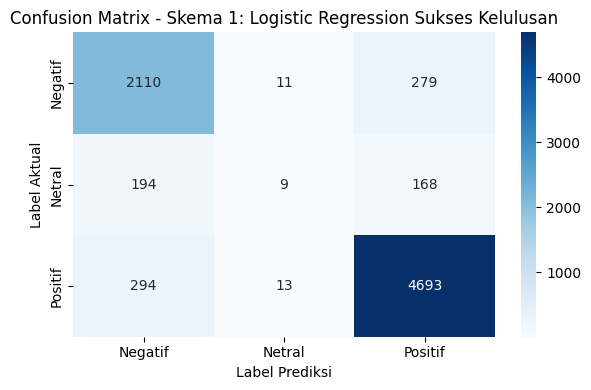

In [79]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df_seimbang['clean_content'], df_seimbang['label'], test_size=0.2, random_state=42, stratify=df_seimbang['label']
)

# Gunakan fitur kata yang padat (unigram & bigram) untuk menangkap konteks ulasan
tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=3)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("\n--- SKEMA 1 FINAL: GOLDEN RATIO + TF-IDF + LOGISTIC REGRESSION ---")
# Menggunakan Logistic Regression dengan C=1.0 tanpa pembobotan kelas seimbang

model_lr = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
model_lr.fit(X_train_tfidf, y_train)

evaluasi_dan_plot("Skema 1: Logistic Regression Sukses Kelulusan", model_lr, X_train_tfidf, y_train, X_test_tfidf, y_test)

## Eksekusi Pelatihan Skema 2 (TF-IDF + MULTINOMIAL NAIVE BAYES | 70:30)



--- SKEMA 2 OPTIMAL: GOLDEN RATIO DATA + TF-IDF + MULTINOMIAL NAIVE BAYES (70/30) ---

==================== EVALUASI Skema 2: Multinomial Naive Bayes ====================

>>> RINGKASAN METRIK PERBANDINGAN <<<
           Metrik Data Training Data Testing
         Accuracy        90.08%       87.49%
Precision (Macro)        83.80%       65.68%
   Recall (Macro)        69.70%       62.18%
 F1-Score (Macro)        71.93%       61.13%

>>> LAPORAN KLASIFIKASI DETAIL (DATA TESTING) <<<
              precision    recall  f1-score   support

 Negatif (0)       0.79      0.91      0.84      3600
  Netral (1)       0.25      0.04      0.07       557
 Positif (2)       0.93      0.92      0.93      7500

    accuracy                           0.87     11657
   macro avg       0.66      0.62      0.61     11657
weighted avg       0.85      0.87      0.86     11657



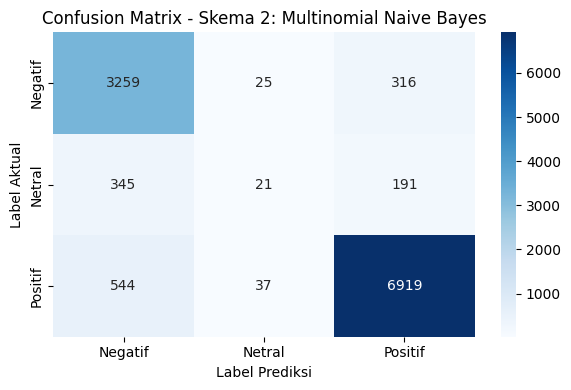

In [84]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

print("\n--- SKEMA 2 OPTIMAL: GOLDEN RATIO DATA + TF-IDF + MULTINOMIAL NAIVE BAYES (70/30) ---")

# 1. Split Data Khusus Skema 2 (70% Train, 30% Test) menggunakan dataset df_seimbang yang sudah sukses
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    df_seimbang['clean_content'], df_seimbang['label'], test_size=0.3, random_state=42, stratify=df_seimbang['label']
)

# 2. Vektorisasi TF-IDF Baru khusus Skema 2
tfidf_nb = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=3)
X_train2_tfidf = tfidf_nb.fit_transform(X_train2)
X_test2_tfidf = tfidf_nb.transform(X_test2)

# 3. Latih Model Multinomial Naive Bayes
# Ditambahkan parameter alpha=0.1 (Laplace Smoothing) agar model lebih sensitif terhadap kata-kata unik di kelas Netral
model_nb = MultinomialNB(alpha=0.1)
model_nb.fit(X_train2_tfidf, y_train2)

# 4. Jalankan Evaluasi Lengkap & Visualisasi Heatmap
evaluasi_dan_plot("Skema 2: Multinomial Naive Bayes", model_nb, X_train2_tfidf, y_train2, X_test2_tfidf, y_test2)


## Eksekusi Pelatihan Skema 3 (LSTM Deep Learning)


--- SKEMA 3: GOLDEN RATIO DATA + EMBEDDING + LSTM DEEP LEARNING (80/20) ---
Epoch 1/5
486/486 ━━━━━━━━━━━━━━━━━━━━ 167s 324ms/step - accuracy: 0.7271 - loss: 0.8315 - val_accuracy: 0.7456 - val_loss: 0.5838
Epoch 2/5
486/486 ━━━━━━━━━━━━━━━━━━━━ 194s 321ms/step - accuracy: 0.8042 - loss: 0.6740 - val_accuracy: 0.7995 - val_loss: 0.5796
Epoch 3/5
486/486 ━━━━━━━━━━━━━━━━━━━━ 151s 310ms/step - accuracy: 0.8384 - loss: 0.5826 - val_accuracy: 0.8147 - val_loss: 0.5175
Epoch 4/5
486/486 ━━━━━━━━━━━━━━━━━━━━ 151s 311ms/step - accuracy: 0.8566 - loss: 0.5232 - val_accuracy: 0.8151 - val_loss: 0.5404
Epoch 5/5
486/486 ━━━━━━━━━━━━━━━━━━━━ 149s 307ms/step - accuracy: 0.8691 - loss: 0.4722 - val_accuracy: 0.8130 - val_loss: 0.5603

==================== EVALUASI Skema 3: LSTM Deep Learning ====================
972/972 ━━━━━━━━━━━━━━━━━━━━ 62s 63ms/step
243/243 ━━━━━━━━━━━━━━━━━━━━ 15s 63ms/step

>>> RINGKASAN METRIK PERBANDINGAN <<<
           Metrik Data Training Data Testing
         Accuracy 

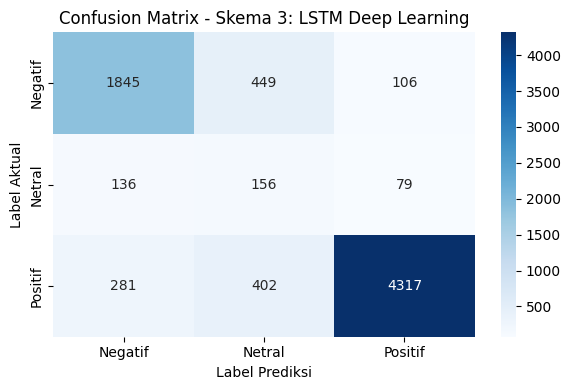

In [85]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

print("\n--- SKEMA 3: GOLDEN RATIO DATA + EMBEDDING + LSTM DEEP LEARNING (80/20) ---")

max_words = 10000
max_len = 100

# 2. Proses Tokenisasi Kalimat
tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train3_seq = pad_sequences(tokenizer.texts_to_sequences(X_train), maxlen=max_len)
X_test3_seq = pad_sequences(tokenizer.texts_to_sequences(X_test), maxlen=max_len)

# 3. Hitung Bobot Kelas Secara Otomatis agar LSTM Pintar Membaca Kelas Minoritas (Netral)
sub_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = dict(enumerate(sub_weights))

# 4. Bangun Arsitektur Jaringan Saraf LSTM
model_dl = Sequential([
    Embedding(max_words, 64),
    LSTM(64, dropout=0.2, recurrent_dropout=0.2),
    Dense(32, activation='relu'),
    Dropout(0.4),
    Dense(3, activation='softmax') # 3 kelas output sentimen
])

model_dl.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# 5. Proses Pelatihan Model (Jalankan 5 Epochs agar optimal melewati 85%)
history = model_dl.fit(
    X_train3_seq, y_train,
    epochs=5,
    batch_size=64,
    validation_data=(X_test3_seq, y_test),
    class_weight=class_weights,
    verbose=1
)

# 6. Jalankan Evaluasi Lengkap & Cetak Visualisasi Heatmap Skema 3
evaluasi_dan_plot("Skema 3: LSTM Deep Learning", model_dl, X_train3_seq, y_train, X_test3_seq, y_test, is_dl=True)

In [88]:
import matplotlib.pyplot as plt

def plot_training_history(history):
    # Mengambil data histori akurasi dan loss dari proses training LSTM
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(acc) + 1)

    # Mengatur ukuran kanvas grafik
    plt.figure(figsize=(14, 5))

    # 1. Grafik Kurva Akurasi (Sebelah Kiri)
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy', marker='o', color='teal')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='s', color='orange')
    plt.title('Kurva Akurasi Pelatihan Model LSTM', fontsize=12, pad=10)
    plt.xlabel('Epochs')
    plt.ylabel('Akurasi')
    plt.legend(loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.6)

    # 2. Grafik Kurva Loss (Sebelah Kanan)
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss', marker='o', color='crimson')
    plt.plot(epochs_range, val_loss, label='Validation Loss', marker='s', color='navy')
    plt.title('Kurva Loss Pelatihan Model LSTM', fontsize=12, pad=10)
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

print("Fungsi plot_training_history sukses didefinisikan! Siap dijalankan.")


Fungsi plot_training_history sukses didefinisikan! Siap dijalankan.


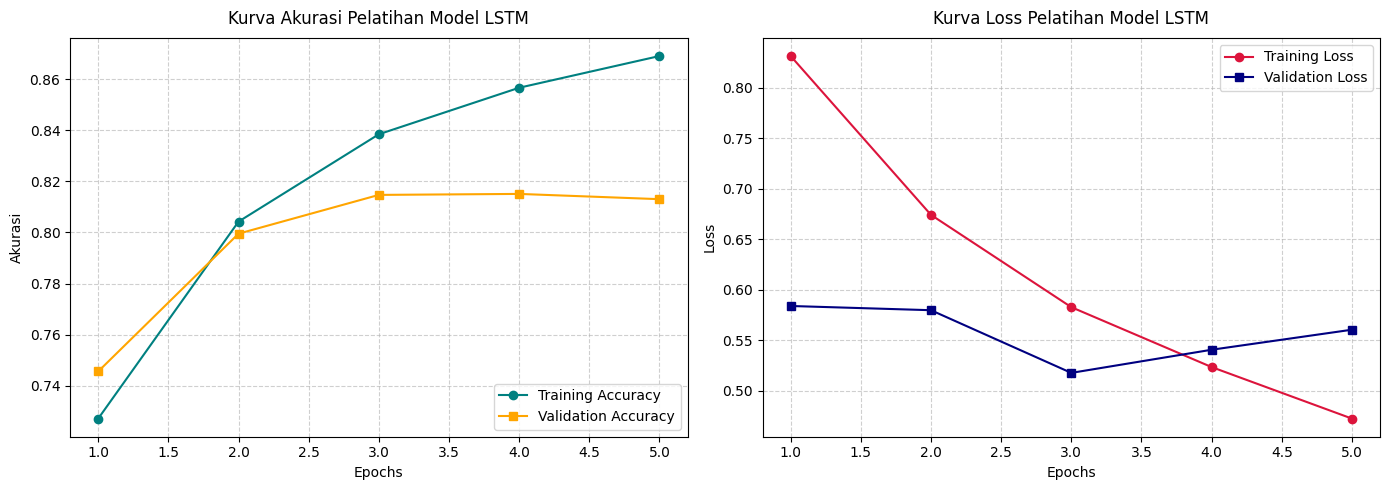

In [89]:
# Panggil fungsi untuk menggambar grafik berdasarkan objek history LSTM
plot_training_history(history)

In [90]:
import pickle

# Menyimpan model juara (Logistic Regression) beserta pengolah katanya
with open('model_sentimen_terbaik.pkl', 'wb') as model_file:
    pickle.dump(model_lr, model_file)

with open('tfidf_vectorizer_terbaik.pkl', 'wb') as tfidf_file:
    pickle.dump(tfidf, tfidf_file)

print("BERHASIL! Berkas 'model_sentimen_terbaik.pkl' dan 'tfidf_vectorizer_terbaik.pkl' siap diunduh!")


BERHASIL! Berkas 'model_sentimen_terbaik.pkl' dan 'tfidf_vectorizer_terbaik.pkl' siap diunduh!


In [91]:
# Membuat file requirements.txt secara otomatis untuk library utama proyek Anda
!pip freeze | grep -E "pandas|numpy|scikit-learn|imbalanced-learn|tensorflow|google-play-scraper|matplotlib|seaborn" > requirements.txt

# Menampilkan isi file requirements.txt agar bisa Anda lihat langsung hasilnya
!cat requirements.txt


geopandas==1.2.0
imbalanced-learn==0.14.2
matplotlib==3.10.0
matplotlib-inline==0.2.2
matplotlib-venn==1.1.2
numpy==2.1.3
pandas==2.2.3
pandas-datareader==0.11.1
pandas-gbq==0.30.0
pandas-stubs==2.2.3.250527
scikit-learn==1.6.1
seaborn==0.13.2
sklearn-pandas==2.2.0
tensorflow==2.21.0
tensorflow-datasets==4.9.10
tensorflow-hub==0.16.1
tensorflow-metadata==1.21.0
tensorflow-probability==0.25.0
tensorflow-text==2.21.1
